# Cora node classification (centroid hypergraph)

Load `data/cora_classification/cora_classification.pickle`. **HMRW:** sweep a **(p, q, r)** grid (same choices as the hedge-prediction notebook), each time embedding once then **stratified *k*-fold CV** with a **class-weight–balanced** logistic regression; append results to **`results/cora_classification/hmrw_pqr_cv.csv`** (skip rows already present for the same p, q, r, walk settings, seed, and CV config).

**Hyper2Vec:** single setting in the next cell for comparison.

A **Parameter sweep** section below implements configurable grids (p, q, r, walks, embedding dimension) with baseline defaults; results go to `hmrw_sweep_cv.csv` / `hyper2vec_sweep_cv.csv`.

Run cells top to bottom.

In [2]:
from pathlib import Path
import pickle

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate
from hypergraphx import Hypergraph

from src.utils import hmrw_embeddings, hyper2vec_embeddings

data_path = Path("data") / "cora_classification" / "cora_classification.pickle"
with open(data_path, "rb") as f:
    bundle = pickle.load(f)

edge_list = bundle["edge_list"]
cls_to_y = bundle["cls_to_y"]
labels = np.asarray(bundle["labels"], dtype=int)

H = Hypergraph(edge_list)
nodes = sorted(H.get_nodes())
n = len(nodes)
y = np.array([labels[int(u)] for u in nodes], dtype=int)
assert len(labels) == n == len(y), (len(labels), n, len(y))

print(f"Loaded {data_path}")
print(f"|V|={n}, |E|={len(H.get_edges())}, classes={len(cls_to_y)}")

rng_split = 42
n_splits = 5
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=rng_split)
scoring = {
    "micro_f1": make_scorer(f1_score, average="micro", zero_division=0),
    "macro_f1": make_scorer(f1_score, average="macro", zero_division=0),
}
print(f"Stratified {n_splits}-fold CV (shuffle=True, random_state={rng_split})")

emb_seed = 42
num_walks = 5
walk_length = 100

Loaded data/cora_classification/cora_classification.pickle
|V|=2708, |E|=2590, classes=7
Stratified 5-fold CV (shuffle=True, random_state=42)


In [ ]:
import pandas as pd
from sklearn.linear_model import GammaRegressor

pqr_grid = [
    # [0.25, 4, 1],
    [0.5, 2, 1],
    [1, 1, 1],
    # [4, 4, 1],
    [2, 0.5, 1],
    # [4, 0.25, 1],
    # [1, 1, 0.5],
    # [1, 1, 2],
    [0.5, 2, 2],
    [2, 0.5, 2],
]

gamma = -1
out_path = Path("results") / "cora_classification" / "hmrw_pqr_cv.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)

rows = []
if out_path.exists():
    rows = pd.read_csv(out_path).to_dict("records")

existing = set()
for r in rows:
    try:
        existing.add(
            (
                float(r["p"]),
                float(r["q"]),
                float(r["r"]),
                int(r["num_walks"]),
                int(r["walk_length"]),
                int(r["emb_seed"]),
                int(r["n_splits"]),
                int(r["cv_random_state"]),
                int(gamma)
            )
        )
    except KeyError:
        continue

clf = LogisticRegression(
    class_weight="balanced",
    max_iter=10_000,
    random_state=rng_split,
    solver="lbfgs",
)

for p, q, r in pqr_grid:
    key = (
        float(p),
        float(q),
        float(r),
        int(num_walks),
        int(walk_length),
        int(emb_seed),
        int(n_splits),
        int(rng_split),
        int(gamma)
    )
    if key in existing:
        print(f"skip existing p={p}, q={q}, r={r}")
        continue

    print(f"\n=== HMRW p={p}, q={q}, r={r} ===")
    X = hmrw_embeddings(
        H,
        p=p,
        q=q,
        r=r,
        gamma=gamma,
        num_walks=num_walks,
        walk_length=walk_length,
        seed=emb_seed,
    )
    res = cross_validate(
        clf,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
    )
    micro_f = res["test_micro_f1"]
    macro_f = res["test_macro_f1"]

    row = {
        "p": p,
        "q": q,
        "r": r,
        "num_walks": num_walks,
        "walk_length": walk_length,
        "emb_seed": emb_seed,
        "n_splits": n_splits,
        "cv_random_state": rng_split,
        "micro_f1_mean": float(micro_f.mean()),
        "micro_f1_std": float(micro_f.std()),
        "macro_f1_mean": float(macro_f.mean()),
        "macro_f1_std": float(macro_f.std()),
    }
    for k, v in enumerate(micro_f):
        row[f"micro_f1_fold{k}"] = float(v)
    for k, v in enumerate(macro_f):
        row[f"macro_f1_fold{k}"] = float(v)

    rows.append(row)
    existing.add(key)
    pd.DataFrame(rows).to_csv(out_path, index=False)
    print(
        f"saved p={p}, q={q}, r={r}: micro={micro_f.mean():.4f}±{micro_f.std():.4f}, "
        f"macro={macro_f.mean():.4f}±{macro_f.std():.4f} -> {out_path}"
    )

results_df = pd.DataFrame(rows)
results_df.sort_values("macro_f1_mean", ascending=False).head(10)

In [ ]:
import pandas as pd

num_walks = 5
walk_length = 100

pqr_grid = [
    # [0.25, 4, 1],
    [0.5, 2, 1],
    [1, 1, 1],
    # [4, 4, 1],
    [2, 0.5, 1],
    # [4, 0.25, 1],
    # [1, 1, 0.5],
    # [1, 1, 2],
]

out_path = Path("results") / "cora_classification" / "hyper2vec_pqr_cv.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)

rows = []
if out_path.exists():
    rows = pd.read_csv(out_path).to_dict("records")

existing = set()
for r in rows:
    try:
        existing.add(
            (
                float(r["p"]),
                float(r["q"]),
                float(0),
                int(r["num_walks"]),
                int(r["walk_length"]),
                int(r["emb_seed"]),
                int(r["n_splits"]),
                int(r["cv_random_state"]),
            )
        )
    except KeyError:
        continue

clf = LogisticRegression(
    class_weight="balanced",
    max_iter=10_000,
    random_state=rng_split,
    solver="lbfgs",
)

for p, q, r in pqr_grid:
    key = (
        float(p),
        float(q),
        float(r),
        int(num_walks),
        int(walk_length),
        int(emb_seed),
        int(n_splits),
        int(rng_split),
    )
    if key in existing:
        print(f"skip existing p={p}, q={q}, r={r}")
        continue

    print(f"\n=== hyper2vec p={p}, q={q} ===")
    X = hyper2vec_embeddings(
        H,
        p=p,
        q=q,
        r=0,
        num_walks=num_walks,
        walk_length=walk_length,
        seed=emb_seed,
    )
    res = cross_validate(
        clf,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
    )
    micro_f = res["test_micro_f1"]
    macro_f = res["test_macro_f1"]

    row = {
        "p": p,
        "q": q,
        "r": 0,
        "num_walks": num_walks,
        "walk_length": walk_length,
        "emb_seed": emb_seed,
        "n_splits": n_splits,
        "cv_random_state": rng_split,
        "micro_f1_mean": float(micro_f.mean()),
        "micro_f1_std": float(micro_f.std()),
        "macro_f1_mean": float(macro_f.mean()),
        "macro_f1_std": float(macro_f.std()),
    }
    for k, v in enumerate(micro_f):
        row[f"micro_f1_fold{k}"] = float(v)
    for k, v in enumerate(macro_f):
        row[f"macro_f1_fold{k}"] = float(v)

    rows.append(row)
    existing.add(key)
    pd.DataFrame(rows).to_csv(out_path, index=False)
    print(
        f"saved p={p}, q={q}, r={r}: micro={micro_f.mean():.4f}±{micro_f.std():.4f}, "
        f"macro={macro_f.mean():.4f}±{macro_f.std():.4f} -> {out_path}"
    )

results_df = pd.DataFrame(rows)
results_df.sort_values("macro_f1_mean", ascending=False).head(10)

In [5]:
out_path = Path("results") / "cora_classification" / "hmrw_pqr_cv.csv"
pd.read_csv(out_path)

,p,q,r,num_walks,walk_length,emb_seed,n_splits,cv_random_state,micro_f1_mean,micro_f1_std,...,micro_f1_fold1,micro_f1_fold2,micro_f1_fold3,micro_f1_fold4,macro_f1_fold0,macro_f1_fold1,macro_f1_fold2,macro_f1_fold3,macro_f1_fold4,gamma
0,0.5,2.0,1,5,100,42,5,42,0.786199,0.015981,...,0.760148,0.778598,0.807763,0.791128,0.788749,0.748799,0.783974,0.804543,0.781724,-1.0
1,1.0,1.0,1,5,100,42,5,42,0.782501,0.009685,...,0.767528,0.787823,0.781885,0.796673,0.779908,0.753203,0.787277,0.776356,0.792187,-1.0
2,2.0,0.5,1,5,100,42,5,42,0.794685,0.015163,...,0.773063,0.789668,0.807763,0.787431,0.810812,0.758845,0.794235,0.797927,0.780474,-1.0
3,0.5,2.0,1,5,100,42,5,42,0.783230,0.011684,...,0.771218,0.789668,0.780037,0.772643,0.795846,0.751691,0.786303,0.769921,0.766017,1.0
4,1.0,1.0,1,5,100,42,5,42,0.790616,0.010445,...,0.785978,0.795203,0.796673,0.772643,0.807638,0.767051,0.790855,0.783859,0.752971,1.0
5,2.0,0.5,1,5,100,42,5,42,0.800953,0.014043,...,0.795203,0.813653,0.805915,0.776340,0.808683,0.780822,0.812749,0.793315,0.773142,1.0
6,0.5,2.0,2,5,100,42,5,42,0.798008,0.016214,...,0.767528,0.806273,0.800370,0.800370,0.816049,0.749741,0.811556,0.796713,0.800966,NaN
7,2.0,0.5,2,5,100,42,5,42,0.801332,0.013348,...,0.776753,0.806273,0.811460,0.798521,0.809243,0.770588,0.810563,0.799970,0.787987,NaN


In [4]:
out_path = Path("results") / "cora_classification" / "hyper2vec_pqr_cv.csv"
pd.read_csv(out_path)

,p,q,r,num_walks,walk_length,emb_seed,n_splits,cv_random_state,micro_f1_mean,micro_f1_std,...,micro_f1_fold0,micro_f1_fold1,micro_f1_fold2,micro_f1_fold3,micro_f1_fold4,macro_f1_fold0,macro_f1_fold1,macro_f1_fold2,macro_f1_fold3,macro_f1_fold4
0,0.5,2.0,0,5,50,42,5,42,0.807601,0.020521,...,0.835793,0.780443,0.822878,0.789279,0.809612,0.834010,0.762164,0.816728,0.772406,0.801419
1,1.0,1.0,0,5,50,42,5,42,0.795416,0.012943,...,0.819188,0.785978,0.795203,0.794824,0.781885,0.812328,0.772624,0.795369,0.784170,0.768492
2,2.0,0.5,0,5,50,42,5,42,0.797264,0.010667,...,0.815498,0.785978,0.800738,0.796673,0.787431,0.811476,0.775825,0.798609,0.779923,0.782938
3,0.5,2.0,0,5,100,42,5,42,0.811298,0.019065,...,0.841328,0.782288,0.815498,0.813309,0.804067,0.836324,0.759792,0.817702,0.804344,0.798757
4,1.0,1.0,0,5,100,42,5,42,0.804656,0.015240,...,0.824723,0.778598,0.802583,0.813309,0.804067,0.819211,0.759893,0.803569,0.805653,0.789888
5,2.0,0.5,0,5,100,42,5,42,0.798003,0.008848,...,0.809963,0.785978,0.806273,0.794824,0.792976,0.806279,0.766170,0.807724,0.783557,0.794264


### Bar plot (CV macro-F1)

One **tall** figure (**vertical** bars, narrow width so they look thin and long): every **HMRW** `(p,q,r)` row (typically 5), then the **top two Hyper2Vec** `(p,q)` runs by macro-F1 (after deduping walks). **Legend** maps bar colour to HMRW vs Hyper2Vec; x-ticks show only `p,q,r` / `p,q`. Dashed **vertical** line between groups.

- **First code cell:** original side-by-side subplots.
- **Next cell:** `%matplotlib inline` + save + `display(Image(...))` → `results/cora_classification/last_plot.png`.


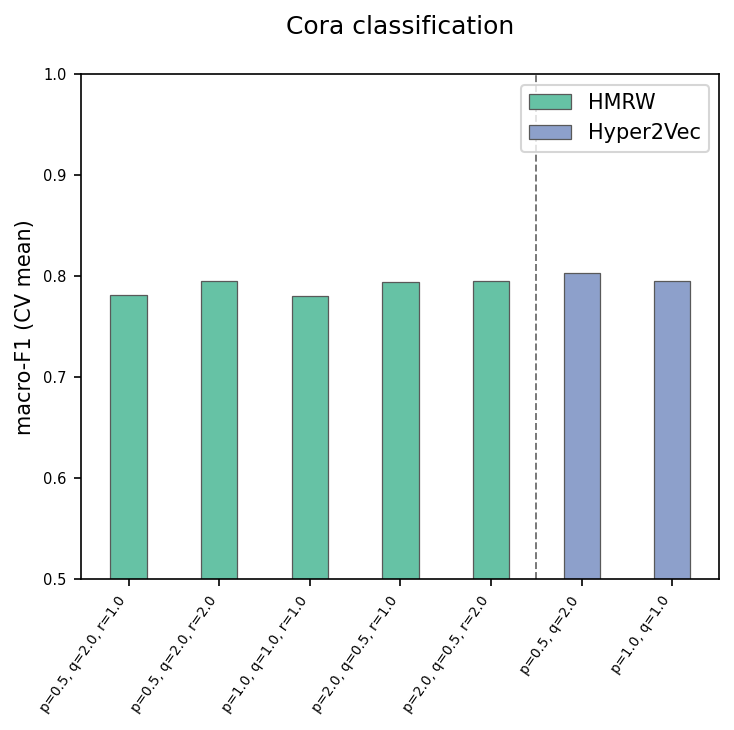

Also saved: /Users/lusineadunts/Documents/omms/Hilary/dissertation/hypergraphs/results/images/cora_classification_macrof1.png


In [18]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

want = 100

hmrw = pd.read_csv(Path("results") / "cora_classification" / "hmrw_pqr_cv.csv")
h2v = pd.read_csv(Path("results") / "cora_classification" / "hyper2vec_pqr_cv.csv")


def pick_rows(df):
    a = df[df["num_walks"] == want]
    if len(a) > 0:
        return a.copy(), "num_walks"
    b = df[df["walk_length"] == want]
    return b.copy(), "walk_length"


hm, tag_hm = pick_rows(hmrw)
h2, tag_h2 = pick_rows(h2v)
used = tag_hm if tag_hm == tag_h2 else f"{tag_hm} (HMRW) vs {tag_h2} (H2V)"

# HMRW: one bar per (p, q, r), best macro when duplicates (e.g. gamma)
hm = hm.sort_values("macro_f1_mean", ascending=False).drop_duplicates(["p", "q", "r"], keep="first")
hm = hm.sort_values(["p", "q", "r"])

# Hyper2Vec: best per (p, q), then top-2 by macro (if fewer rows exist, plot all)
h2 = h2.sort_values("macro_f1_mean", ascending=False).drop_duplicates(["p", "q"], keep="first")
if len(h2) > 2:
    h2 = h2.nlargest(2, "macro_f1_mean")
h2 = h2.sort_values(["p", "q"])

labels = []
vals = []
c_hmrw = plt.cm.Set2(0)
c_h2v = plt.cm.Set2(2)

for _, r in hm.iterrows():
    labels.append(f"p={r['p']}, q={r['q']}, r={r['r']}")
    vals.append(float(r["macro_f1_mean"]))

for _, r in h2.iterrows():
    labels.append(f"p={r['p']}, q={r['q']}")
    vals.append(float(r["macro_f1_mean"]))

n_hm = len(hm)
n_h2 = len(h2)
n = len(vals)
x = np.arange(n)
# Tall figure + narrow bars: vertical bars read as thin and long
fig_w = 5

fig_h = 5.0
fig, ax = plt.subplots(figsize=(fig_w, fig_h))

bar_w = 0.4
if n_hm > 0:
    ax.bar(
        x[:n_hm],
        vals[:n_hm],
        width=bar_w,
        color=c_hmrw,
        edgecolor="0.35",
        linewidth=0.6,
        label="HMRW",
    )
if n_h2 > 0:
    ax.bar(
        x[n_hm:],
        vals[n_hm:],
        width=bar_w,
        color=c_h2v,
        edgecolor="0.35",
        linewidth=0.6,
        label="Hyper2Vec",
    )
ax.legend(loc="upper right")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=55, ha="right", fontsize=6.5)
ax.tick_params(axis="y", labelsize=7)
ax.set_ylabel("macro-F1 (CV mean)")
ax.set_ylim(0.5, 1.0)
ax.set_title(
    f"Cora classification\n"
)

if len(hm) > 0 and len(h2) > 0:
    ax.axvline(x=len(hm) - 0.5, color="0.45", linewidth=0.9, linestyle="--")

plt.tight_layout()

outfig = Path("results") / "images" / "cora_classification_macrof1.png"
outfig.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(outfig, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(outfig)))
print("Also saved:", outfig.resolve())


### Parameter sweep (CV results)

Grids (see intro): **p**, **q** ∈ {0.25, 0.5, 1, 2, 4}; **r** ∈ {0.25, 1, 2}; **walk_length**; **num_walks**; **dim** (embedding size).

Defaults when an axis is fixed: **p=q=r=1**, **gamma=-1** (HMRW), **num_walks=5**, **walk_length=40**, **dim=64**.

Results append to **`results/cora_classification/hmrw_sweep_cv.csv`** and **`hyper2vec_sweep_cv.csv`** (separate from the smaller `*_pqr_cv.csv` tables). Each row includes **`dim`**; dedupe skips identical `(p,q,r, num_walks, walk_length, dim, emb_seed, n_splits, cv_random_state, gamma)` for HMRW (Hyper2Vec omits gamma in the key but stores `r` in the row).

**`SWEEP_MODE`** in the next cell controls which jobs run. Use **`one_at_a_time`** (recommended) to vary exactly one parameter while all others stay at defaults; use **`full_factorial`** only with **`SWEEP_MAX_RUNS`**.


In [ ]:
from pathlib import Path

import pandas as pd

# Grids from the sweep spec
P_GRID = [0.25, 0.5, 1, 2, 4]
Q_GRID = [0.25, 0.5, 1, 2, 4]
R_GRID = [0.25, 1, 2]
WALK_LENGTH_GRID = [10, 20, 40, 100, 200]
NUM_WALKS_GRID = [2, 4, 8, 10, 20]
DIM_GRID = [16, 32, 64, 128, 256]

# Fixed defaults (all non-swept parameters stay at these values)
DEFAULTS = dict(p=1.0, q=1.0, r=1.0, walk_length=40, num_walks=5, dim=64, gamma=-1)

OUT_HMRW = Path("results") / "cora_classification" / "hmrw_sweep_cv.csv"
OUT_HMRW.parent.mkdir(parents=True, exist_ok=True)


def one_at_a_time_jobs(defaults):
    jobs = []
    for p in P_GRID:
        jobs.append({**defaults, "p": p})
    for q in Q_GRID:
        jobs.append({**defaults, "q": q})
    for r in R_GRID:
        jobs.append({**defaults, "r": r})
    for wl in WALK_LENGTH_GRID:
        jobs.append({**defaults, "walk_length": wl})
    for nw in NUM_WALKS_GRID:
        jobs.append({**defaults, "num_walks": nw})
    for d in DIM_GRID:
        jobs.append({**defaults, "dim": d})
    return jobs


rows = pd.read_csv(OUT_HMRW).to_dict("records") if OUT_HMRW.exists() else []

existing = {
    (
        float(r["p"]),
        float(r["q"]),
        float(r["r"]),
        int(r["num_walks"]),
        int(r["walk_length"]),
        int(r["dim"]),
        int(r["emb_seed"]),
        int(r["n_splits"]),
        int(r["cv_random_state"]),
        int(r["gamma"]),
    )
    for r in rows
    if all(k in r for k in ["p", "q", "r", "num_walks", "walk_length", "dim", "emb_seed", "n_splits", "cv_random_state", "gamma"])
}

clf = LogisticRegression(
    class_weight="balanced",
    max_iter=10_000,
    random_state=rng_split,
    solver="lbfgs",
)

for pr in one_at_a_time_jobs(DEFAULTS):
    p, q, r = float(pr["p"]), float(pr["q"]), float(pr["r"])
    num_walks = int(pr["num_walks"])
    walk_length = int(pr["walk_length"])
    dim = int(pr["dim"])
    gamma = int(pr["gamma"])

    key = (p, q, r, num_walks, walk_length, dim, int(emb_seed), int(n_splits), int(rng_split), gamma)
    if key in existing:
        print(f"skip HMRW p={p} q={q} r={r} nw={num_walks} wl={walk_length} dim={dim} g={gamma}")
        continue

    X = hmrw_embeddings(
        H,
        p=p,
        q=q,
        r=r,
        gamma=gamma,
        num_walks=num_walks,
        walk_length=walk_length,
        dim=dim,
        seed=emb_seed,
    )
    res = cross_validate(clf, X, y, cv=cv, scoring=scoring, n_jobs=1)
    micro_f = res["test_micro_f1"]
    macro_f = res["test_macro_f1"]

    row = {
        "p": p,
        "q": q,
        "r": r,
        "num_walks": num_walks,
        "walk_length": walk_length,
        "dim": dim,
        "gamma": gamma,
        "emb_seed": emb_seed,
        "n_splits": n_splits,
        "cv_random_state": rng_split,
        "micro_f1_mean": float(micro_f.mean()),
        "micro_f1_std": float(micro_f.std()),
        "macro_f1_mean": float(macro_f.mean()),
        "macro_f1_std": float(macro_f.std()),
    }
    for k, v in enumerate(micro_f):
        row[f"micro_f1_fold{k}"] = float(v)
    for k, v in enumerate(macro_f):
        row[f"macro_f1_fold{k}"] = float(v)

    rows.append(row)
    existing.add(key)
    pd.DataFrame(rows).to_csv(OUT_HMRW, index=False)
    print(f"saved p={p} q={q} r={r} wl={walk_length} nw={num_walks} dim={dim}")

pd.DataFrame(rows).sort_values("macro_f1_mean", ascending=False).head(12)


skip HMRW p=0.25 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=0.5 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=2.0 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=4.0 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=0.25 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=0.5 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=2.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=4.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=0.25 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=2.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=10 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=20 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=100 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=5 wl=200 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.0 nw=2 wl=40 dim=64 g=-1
skip HMRW p=1.0 q=1.0 r=1.

,p,q,r,num_walks,walk_length,dim,gamma,emb_seed,n_splits,cv_random_state,...,micro_f1_fold0,micro_f1_fold1,micro_f1_fold2,micro_f1_fold3,micro_f1_fold4,macro_f1_fold0,macro_f1_fold1,macro_f1_fold2,macro_f1_fold3,macro_f1_fold4
94,1.0,1.0,1.0,10,10,256,-1,42,5,42,...,0.826568,0.808118,0.837638,0.804067,0.820702,0.825271,0.794989,0.830718,0.797952,0.805620
104,1.0,1.0,1.0,2,20,256,-1,42,5,42,...,0.821033,0.802583,0.833948,0.811460,0.820702,0.811017,0.783813,0.828539,0.795477,0.808416
99,1.0,1.0,1.0,20,10,256,-1,42,5,42,...,0.830258,0.787823,0.811808,0.820702,0.804067,0.825225,0.774086,0.805063,0.815446,0.789359
79,1.0,1.0,1.0,2,10,256,-1,42,5,42,...,0.833948,0.789668,0.828413,0.800370,0.824399,0.823217,0.768260,0.819633,0.778946,0.807743
109,1.0,1.0,1.0,4,20,256,-1,42,5,42,...,0.841328,0.778598,0.813653,0.807763,0.809612,0.830418,0.765844,0.806344,0.794636,0.798974
130,1.0,1.0,1.0,5,40,256,-1,42,5,42,...,0.815498,0.784133,0.817343,0.794824,0.800370,0.818766,0.777830,0.813681,0.788112,0.787252
89,1.0,1.0,1.0,8,10,256,-1,42,5,42,...,0.822878,0.797048,0.830258,0.781885,0.800370,0.815802,0.778866,0.828532,0.772221,0.783137
126,1.0,1.0,1.0,20,40,64,-1,42,5,42,...,0.811808,0.791513,0.791513,0.807763,0.798521,0.814587,0.779968,0.799674,0.796304,0.787087
103,1.0,1.0,1.0,2,20,128,-1,42,5,42,...,0.809963,0.765683,0.822878,0.787431,0.802218,0.797629,0.750649,0.818270,0.776890,0.793393
124,1.0,1.0,1.0,8,40,64,-1,42,5,42,...,0.804428,0.769373,0.806273,0.791128,0.783734,0.801940,0.757609,0.809264,0.784679,0.775834


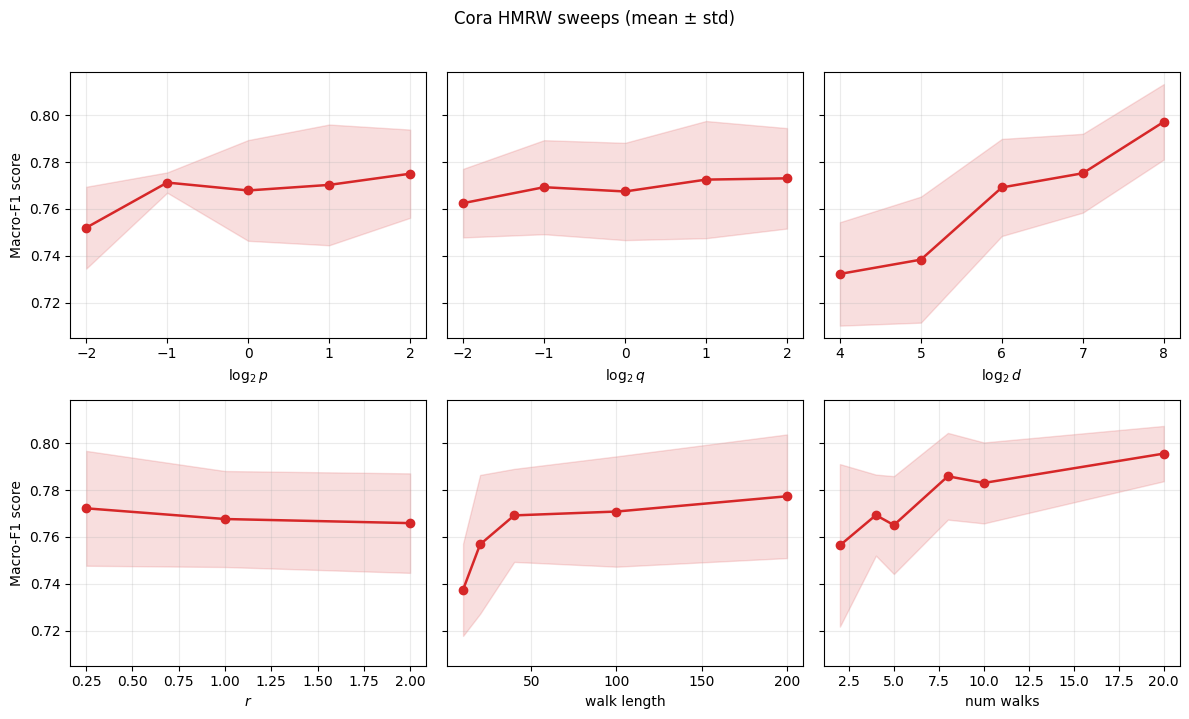

,swept_param,value,macro_f1_mean,macro_f1_std
0,p,0.25,0.752027,0.017437
1,p,0.50,0.771250,0.004326
2,p,1.00,0.767894,0.021459
3,p,2.00,0.770259,0.025718
4,p,4.00,0.775029,0.018802
5,q,0.25,0.762483,0.014606
6,q,0.50,0.769278,0.020032
7,q,1.00,0.767456,0.020723
8,q,2.00,0.772513,0.024962
9,q,4.00,0.773056,0.021399


In [23]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


base = Path("results") / "cora_classification"


def plot_sweep_panels(csv_path, title):
    if not csv_path.exists():
        print(f"Missing: {csv_path}")
        return

    # hmrw_sweep_cv.csv is already sweep-only
    df = pd.read_csv(csv_path)

    specs = [
        ("p", r"$\log_2 p$", True),
        ("q", r"$\log_2 q$", True),
        ("dim", r"$\log_2 d$", True),
        ("r", r"$r$", False),
        ("walk_length", "walk length", False),
        ("num_walks", "num walks", False),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=True)
    fig.suptitle(title, y=1.02)

    summary_blocks = []

    for ax, (col, xlabel, use_log2) in zip(axes.ravel(), specs):
        if col not in df.columns:
            ax.set_visible(False)
            continue

        grp = (
            df.groupby(col, as_index=False)
            .agg(mean=("macro_f1_mean", "mean"), std=("macro_f1_std", "mean"))
            .sort_values(col)
        )
        grp["std"] = grp["std"].fillna(0.0)

        summary = grp.rename(columns={col: "value", "mean": "macro_f1_mean", "std": "macro_f1_std"}).copy()
        summary["swept_param"] = col
        summary_blocks.append(summary[["swept_param", "value", "macro_f1_mean", "macro_f1_std"]])

        x = grp[col].astype(float).to_numpy()
        y = grp["mean"].to_numpy()
        s = grp["std"].to_numpy()

        if use_log2:
            keep = x > 0
            x, y, s = np.log2(x[keep]), y[keep], s[keep]

        ax.plot(x, y, marker="o", linewidth=1.8, color="tab:red")
        ax.fill_between(x, y - s, y + s, alpha=0.15, color="tab:red")
        # ax.errorbar(x, y, yerr=s, fmt="none", ecolor="0.35", elinewidth=1.0, capsize=3)
        ax.set_xlabel(xlabel)
        ax.grid(alpha=0.25)

    axes[0, 0].set_ylabel("Macro-F1 score")
    axes[1, 0].set_ylabel("Macro-F1 score")
    plt.tight_layout()
    plt.show()
    outfig = Path("results") / "images" / "cora_classification_hmrw_sweep.png"
    fig.savefig(outfig, dpi=150, bbox_inches="tight")

    if summary_blocks:
        display(pd.concat(summary_blocks, ignore_index=True))


plot_sweep_panels(base / "hmrw_sweep_cv.csv", "Cora HMRW sweeps (mean ± std)")



In [3]:
from pathlib import Path

import pandas as pd

# Grids from the sweep spec
P_GRID = [0.25, 0.5, 1, 2, 4]
Q_GRID = [0.25, 0.5, 1, 2, 4]
R_GRID = [0.5, 1, 2]
WALK_LENGTH_GRID = [10, 40, 100, 200]
NUM_WALKS_GRID = [2, 10, 20, 50]
DIM_GRID = [16, 64, 128, 256, 256*2]

# Fixed defaults (all non-swept parameters stay at these values)
DEFAULTS = dict(p=1.0, q=1.0, r=1.0, walk_length=100, num_walks=20, dim=128, gamma=-1)

OUT_HMRW = Path("results") / "cora_classification_degreesremoved" / "hmrw_sweep_updated_cv.csv"
OUT_HMRW.parent.mkdir(parents=True, exist_ok=True)


def one_at_a_time_jobs(defaults):
    jobs = []
    for p in P_GRID:
        jobs.append({**defaults, "p": p})
    for q in Q_GRID:
        jobs.append({**defaults, "q": q})
    for r in R_GRID:
        jobs.append({**defaults, "r": r})
    for wl in WALK_LENGTH_GRID:
        jobs.append({**defaults, "walk_length": wl})
    for nw in NUM_WALKS_GRID:
        jobs.append({**defaults, "num_walks": nw})
    for d in DIM_GRID:
        jobs.append({**defaults, "dim": d})
    return jobs


rows = pd.read_csv(OUT_HMRW).to_dict("records") if OUT_HMRW.exists() else []

existing = {
    (
        float(r["p"]),
        float(r["q"]),
        float(r["r"]),
        int(r["num_walks"]),
        int(r["walk_length"]),
        int(r["dim"]),
        int(r["emb_seed"]),
        int(r["n_splits"]),
        int(r["cv_random_state"]),
        int(r["gamma"]),
    )
    for r in rows
    if all(k in r for k in ["p", "q", "r", "num_walks", "walk_length", "dim", "emb_seed", "n_splits", "cv_random_state", "gamma"])
}

clf = LogisticRegression(
    class_weight="balanced",
    max_iter=10_000,
    random_state=rng_split,
    solver="lbfgs",
)

for pr in one_at_a_time_jobs(DEFAULTS):
    p, q, r = float(pr["p"]), float(pr["q"]), float(pr["r"])
    num_walks = int(pr["num_walks"])
    walk_length = int(pr["walk_length"])
    dim = int(pr["dim"])
    gamma = int(pr["gamma"])

    key = (p, q, r, num_walks, walk_length, dim, int(emb_seed), int(n_splits), int(rng_split), gamma)
    if key in existing:
        print(f"skip HMRW p={p} q={q} r={r} nw={num_walks} wl={walk_length} dim={dim} g={gamma}")
        continue

    X = hmrw_embeddings(
        H,
        p=p,
        q=q,
        r=r,
        gamma=gamma,
        delta=0.0,
        num_walks=num_walks,
        walk_length=walk_length,
        dim=dim,
        seed=emb_seed,
    )
    res = cross_validate(clf, X, y, cv=cv, scoring=scoring, n_jobs=1)
    micro_f = res["test_micro_f1"]
    macro_f = res["test_macro_f1"]

    row = {
        "p": p,
        "q": q,
        "r": r,
        "num_walks": num_walks,
        "walk_length": walk_length,
        "dim": dim,
        "gamma": gamma,
        "delta": 0.0,
        "emb_seed": emb_seed,
        "n_splits": n_splits,
        "cv_random_state": rng_split,
        "micro_f1_mean": float(micro_f.mean()),
        "micro_f1_std": float(micro_f.std()),
        "macro_f1_mean": float(macro_f.mean()),
        "macro_f1_std": float(macro_f.std()),
    }
    for k, v in enumerate(micro_f):
        row[f"micro_f1_fold{k}"] = float(v)
    for k, v in enumerate(macro_f):
        row[f"macro_f1_fold{k}"] = float(v)

    rows.append(row)
    existing.add(key)
    pd.DataFrame(rows).to_csv(OUT_HMRW, index=False)
    print(f"saved p={p} q={q} r={r} wl={walk_length} nw={num_walks} dim={dim}")

pd.DataFrame(rows).sort_values("macro_f1_mean", ascending=False).head(12)


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

saved p=0.25 q=1.0 r=1.0 wl=100 nw=20 dim=128


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

KeyboardInterrupt: 

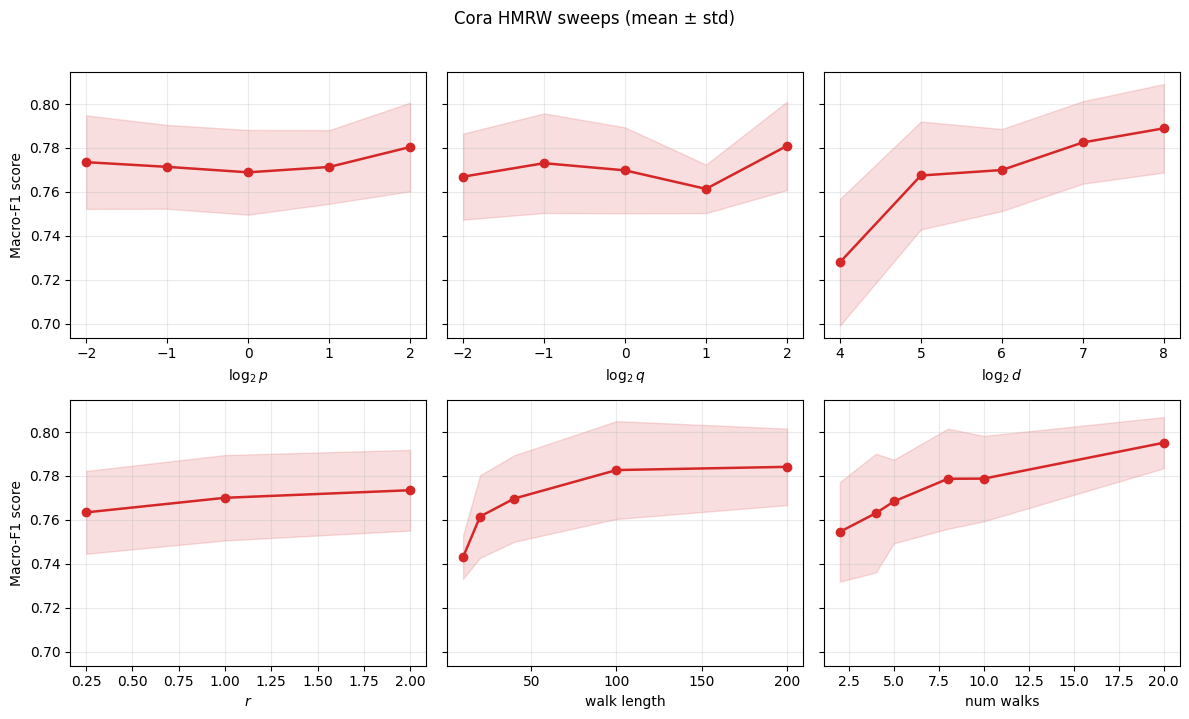

,swept_param,value,macro_f1_mean,macro_f1_std
0,p,0.25,0.773522,0.021278
1,p,0.50,0.771387,0.019077
2,p,1.00,0.768895,0.019291
3,p,2.00,0.771331,0.016770
4,p,4.00,0.780422,0.020175
5,q,0.25,0.766914,0.019577
6,q,0.50,0.773053,0.022679
7,q,1.00,0.769801,0.019570
8,q,2.00,0.761360,0.011040
9,q,4.00,0.780940,0.020135


In [6]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


base = Path("results") / "cora_classification_degreesremoved/"


def plot_sweep_panels(csv_path, title):
    if not csv_path.exists():
        print(f"Missing: {csv_path}")
        return

    # hmrw_sweep_cv.csv is already sweep-only
    df = pd.read_csv(csv_path)

    specs = [
        ("p", r"$\log_2 p$", True),
        ("q", r"$\log_2 q$", True),
        ("dim", r"$\log_2 d$", True),
        ("r", r"$r$", False),
        ("walk_length", "walk length", False),
        ("num_walks", "num walks", False),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=True)
    fig.suptitle(title, y=1.02)

    summary_blocks = []

    for ax, (col, xlabel, use_log2) in zip(axes.ravel(), specs):
        if col not in df.columns:
            ax.set_visible(False)
            continue

        grp = (
            df.groupby(col, as_index=False)
            .agg(mean=("macro_f1_mean", "mean"), std=("macro_f1_std", "mean"))
            .sort_values(col)
        )
        grp["std"] = grp["std"].fillna(0.0)

        summary = grp.rename(columns={col: "value", "mean": "macro_f1_mean", "std": "macro_f1_std"}).copy()
        summary["swept_param"] = col
        summary_blocks.append(summary[["swept_param", "value", "macro_f1_mean", "macro_f1_std"]])

        x = grp[col].astype(float).to_numpy()
        y = grp["mean"].to_numpy()
        s = grp["std"].to_numpy()

        if use_log2:
            keep = x > 0
            x, y, s = np.log2(x[keep]), y[keep], s[keep]

        ax.plot(x, y, marker="o", linewidth=1.8, color="tab:red")
        ax.fill_between(x, y - s, y + s, alpha=0.15, color="tab:red")
        # ax.errorbar(x, y, yerr=s, fmt="none", ecolor="0.35", elinewidth=1.0, capsize=3)
        ax.set_xlabel(xlabel)
        ax.grid(alpha=0.25)

    axes[0, 0].set_ylabel("Macro-F1 score")
    axes[1, 0].set_ylabel("Macro-F1 score")
    plt.tight_layout()
    plt.show()
    outfig = Path("results") / "images" / "cora_classification_hmrw_sweep.png"
    fig.savefig(outfig, dpi=150, bbox_inches="tight")

    if summary_blocks:
        display(pd.concat(summary_blocks, ignore_index=True))


plot_sweep_panels(base / "hmrw_sweep_cv.csv", "Cora HMRW sweeps (mean ± std)")

